# Depth of the heat-cold storage

## Model
Note:
- Heat equation in the ground: ∂T/∂t = κ ∂²T/∂z², with z the depth (z = 0 at the surface, positive going down) and κ = 50.
- T_surface has a period of 24, so t is in hours. I take z in m, so κ = 50 m²/h.
- T_surface(t) = a - b sin(2πt/24) with a = 15 (the mean temperature) and b = 5 (the fluctuation), so the surface goes between 10 and 20 degrees.
- "Fluctuates with 5 degrees" is b = 5, so I read "does not fluctuate more than 1 degree" the same way: the amplitude at the storage must be ≤ 1, so T stays between 14 and 16 degrees.

## Boundaries and starting condition
Note:
- Dirichlet boundary: I fix the value of T at the boundary. A Neumann boundary would fix ∂T/∂z instead (the heat flux), like ∂T/∂r = 0 at the center of the nuclear waste rod in section 7.8 of the book. Here I know the temperature at both ends, so I use Dirichlet at both.
- Top, z = 0: T = T_surface(t).
- Bottom, z = L: T = 15. Deep in the ground the temperature is just the mean. The bottom has to be much deeper than the storage, so that it does not change the answer. With 100 nodes I take L = 99 m, so the nodes are h = 1 m apart.
- Time: I start at t = 0 and stop at t = 10 days = 240 h, with dt = 0.01 h.
- Starting condition: T = 15 everywhere. This is the same as both boundaries at t = 0 (T_surface(0) = 15), so there is no jump at the start. The ground still needs some time to forget the starting condition, so I only use the last day, and I check that the day before gives the same.

## Method
Note:
- I use the Crank–Nicolson method from section 7.7 of the book (Eq. 7.93). The book also uses it for the temperature field around a nuclear waste rod (section 7.8):

$$(2 - H)\,T(t + \tau) = (2 + H)\,T(t), \qquad H\,T_i = \gamma\,(T_{i+1} + T_{i-1} - 2T_i), \qquad \gamma = \frac{\kappa\tau}{h^2}$$

- τ = dt is the time step. H T_i is the three-point formula for ∂²T/∂z² times κτ, and Crank–Nicolson takes the average of it at t and t + τ.
- It is stable for any γ. The simpler Euler (forward difference) method is only stable for γ ≤ 1/2 (section 7.7), and here γ = 50·0.01/1² = 0.5 is right at that limit.
- T(t + τ) is on the left side, so every step I have to solve a linear system. The matrix on the left side does not change, so I do the LU decomposition once and then only the forward and backward substitution every step, like in section 7.8.
- The Dirichlet boundaries go into the matrix: the first row just says T_0 = T_surface(t + τ) and the last row says T_(N-1) = 15.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import lu_factor, lu_solve

In [2]:
kappa = 50     #heat diffusion coefficient (m^2/h)
a, b = 15, 5   #mean temperature and fluctuation (degrees)
N = 100        #number of nodes
L = 99         #depth of the bottom (m)
dt = 0.01      #time step (h)
days = 10      #simulation time (days)

z = np.linspace(0, L, N) #depth of the nodes: 0, 1, ..., 99 m
h = z[1] - z[0]          #distance between the nodes, 1 m
gamma = kappa*dt/h**2

# Surface temperature (top boundary), t in hours
def T_surface(t):
    return a - b*np.sin(2*np.pi*t/24)

In [3]:
# Crank-Nicolson matrices (Eq. 7.93): (2 - H) T(t + dt) = (2 + H) T(t)
# H T_i = gamma*(T_(i+1) + T_(i-1) - 2 T_i) for the inside nodes i = 1, ..., N-2
H = np.zeros((N, N))
for i in range(1, N - 1):
    H[i, i-1], H[i, i], H[i, i+1] = gamma, -2*gamma, gamma
A = 2*np.eye(N) - H #left side
B = 2*np.eye(N) + H #right side

# Dirichlet boundaries: row 0 and row N-1 of A just say T_0 = (value) and T_(N-1) = (value)
# The values are put in the right-hand side every step, so B is 0 in these rows
A[0, 0], A[-1, -1] = 1, 1
B[0, 0], B[-1, -1] = 0, 0

# A is the same in every step, so I do the LU decomposition only once
lu = lu_factor(A)

In [4]:
# Time loop from t = 0 to t = 10 days
# Starting condition: T = 15 everywhere
# T_all keeps T at every time step (rows) and every depth (columns)
nt = int(round(days*24/dt)) #number of time steps
T = np.full(N, 15.0)
T_all = np.zeros((nt + 1, N))
T_all[0] = T

for n in range(nt):
    rhs = B @ T                     #right side (2 + H) T(t)
    rhs[0] = T_surface((n + 1)*dt)  #top: surface temperature at the new time
    rhs[-1] = 15                    #bottom: mean temperature
    T = lu_solve(lu, rhs)           #forward and backward substitution
    T_all[n + 1] = T

t = np.arange(nt + 1)*dt #time of every step (h)

In [5]:
# Amplitude at every depth during one day: (max - min)/2
# day: which day (0 is the first day)
def amplitude(day):
    one_day = (t >= day*24) & (t <= (day + 1)*24)
    return (T_all[one_day].max(axis=0) - T_all[one_day].min(axis=0))/2

amp = amplitude(days - 1) #last day

# Check that the starting condition is forgotten: the day before should give the same
print("largest difference with the day before:", np.max(np.abs(amp - amplitude(days - 2))))

# Depth where the amplitude is 1 degree, with linear interpolation between the nodes
# np.interp needs increasing values, and amp decreases with z, so I flip both arrays
depth = np.interp(1, amp[::-1], z[::-1])
print("depth where the amplitude is 1 degree:", depth, "m")

# Check: exact amplitude for a ground that goes down forever, b*exp(-z/delta)
omega = 2*np.pi/24
delta = np.sqrt(2*kappa/omega)
print("exact depth:", delta*np.log(b/1), "m")

largest difference with the day before: 5.182668918024547e-06
depth where the amplitude is 1 degree: 31.438115009148422 m
exact depth: 31.45501627068373 m


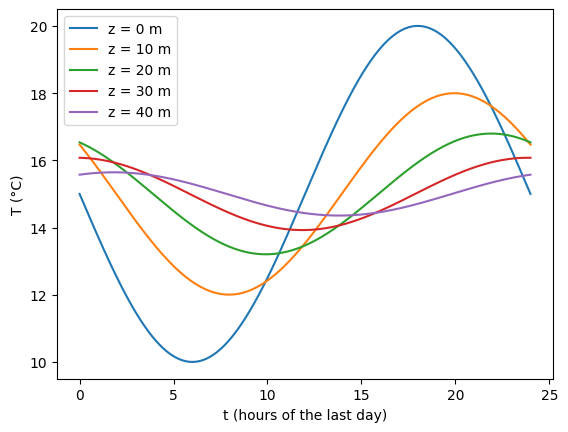

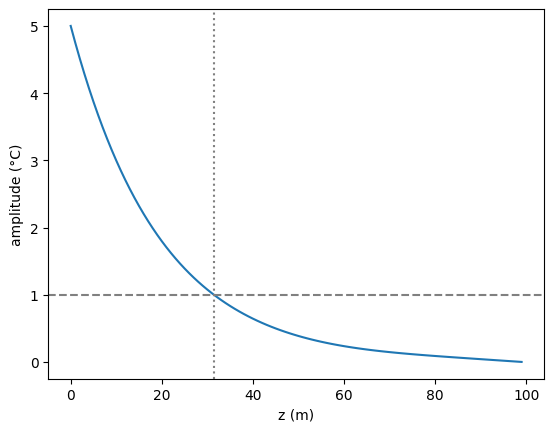

In [6]:
# Temperature during the last day at some depths
fig, ax = plt.subplots()
last = t >= (days - 1)*24
for zi in [0, 10, 20, 30, 40]:
    ax.plot(t[last] - (days - 1)*24, T_all[last, zi], label=f'z = {zi} m') #h = 1 m, so node zi is at depth zi m
ax.set_xlabel('t (hours of the last day)'); ax.set_ylabel('T (°C)'); ax.legend()
plt.show()

# Amplitude against depth, with the 1 degree line
fig, ax = plt.subplots()
ax.plot(z, amp)
ax.axhline(1, color='gray', ls='--')    #1 degree
ax.axvline(depth, color='gray', ls=':') #depth found above
ax.set_xlabel('z (m)'); ax.set_ylabel('amplitude (°C)')
plt.show()

## Result
Note:
- The last two days give the same amplitude (difference about 5·10^-6), so the starting condition is forgotten.
- The fluctuation gets smaller with depth, and the peaks come later deeper in the ground.
- The amplitude drops to 1 degree at z ≈ 31.4 m. Therefore, the cold storage should be at least about 31.4 m deep.
- Check: for a ground that goes down forever, the exact amplitude is b e^(-z/δ) with δ = √(2κ/ω) and ω = 2π/24. It is 1 degree at z = δ ln 5 ≈ 31.5 m, almost the same. So the bottom at 99 m is deep enough.